# CMT307 Lab 1

## Task 1: a very brief machine learning modelling process


*   Get data: the problem
*   Know the data: EDA (Exploratory data analysis)
*   Process the data: pre-processing
*   Build model(s): modelling
*   Evaluate the model: evaluation

Note the purpose of this example is to show the essential stages in the pipeline of a ML project, and the contents of the above stages are extremely simplified. A real ML project will contain a lot lot more than this example


In [1]:
from sklearn import datasets, svm
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd
#import numpy as np

In [2]:
pd.set_option('display.max_columns', None, 'max_colwidth', None, 'display.expand_frame_repr', False) # print all columns in full, prevent line break

## Get data

In [3]:
# get iris data
iris = datasets.load_iris()

# show the data
print(iris.data)
print(iris.target)

#print(np.c_[iris.data,iris.target])


[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [4]:
# arrange the data into input and output
X   = iris.data     # input
y   = iris.target   # output

n   = X.shape[0]    # number of data points
print(n)

150


In [5]:
# split the data set into training and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## EDA
here contains some data description and an extremely basic plot only, no meaninful EDA work here in the sense of a real ML project

In [6]:
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

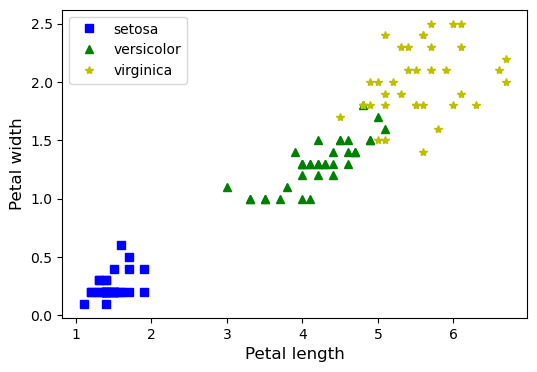

In [7]:
# show two dimensions of the data, petal length and petal width

#plt.scatter(X_train[:, 2], X_train[:,3], c=y_train)   # petal length, petal width

plt.figure(figsize=(6, 4))

plt.plot(X_train[y_train==0, 2], X_train[y_train==0, 3], "bs")
plt.plot(X_train[y_train==1, 2], X_train[y_train==1, 3], "g^")
plt.plot(X_train[y_train==2, 2], X_train[y_train==2, 3], "y*")

plt.xlabel("Petal length", fontsize=12)
plt.ylabel("Petal width", fontsize=12)

plt.legend(['setosa', 'versicolor', 'virginica'])

## Data Preprocessing

In [8]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler() # use default value to convert features into range of [0, 1]
scaler.fit(X_train)     # fit the model on the training data

X_train_scaled = scaler.transform(X_train)  # transform the training data using the fitted model above
X_test_scaled = scaler.transform(X_test)    # transform the test data using the same fitted model above


## Data modelling

In [ ]:
# specify a classification model of support vector machine, using default hyperparameters
# in real ML project, we normally need to optimise model hyperparameters
#clf = svm.LinearSVC()  
clf = svm.SVC()

In [ ]:
# train the classifer on the training data
clf.fit(X_train_scaled, y_train)

# In this first example, the classifier is fitted using default hyperparameters.
# Note hyperparameters are usually needed to be optimised.

## Model evaluation

In [ ]:
# use the trained model to predict iris types of test data
y_pred = clf.predict(X_test_scaled)
y_pred

In [ ]:
from sklearn.metrics import accuracy_score

# calculate prediction accuracy
accuracy_score(y_test, y_pred)

## Another way of loading Iris data

In [ ]:
# you can use UCI package to get a dataset from UCI machine learning repository
#!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
iris = fetch_ucirepo(id=53)

# data (as pandas dataframes)
X = iris.data.features
y = iris.data.targets

# metadata
print(iris.metadata)

# variable information
print(iris.variables)


In [ ]:
print(iris.data)